<div style="background:linear-gradient(135deg,#1e1b4b 0%,#4338ca 55%,#6366f1 100%);border-radius:18px;padding:34px 30px;color:#fff;font-family:Inter,Segoe UI,sans-serif">
  <div style="font-size:12px;letter-spacing:3px;color:#c7d2fe;font-weight:700;text-transform:uppercase">Chapter 130 · Take It Further</div>
  <div style="font-size:34px;font-weight:900;line-height:1.1;margin:10px 0 6px">Operationalizing the Model &#183; Take It Further</div>
  <div style="font-size:15px;color:#e0e7ff;max-width:740px;line-height:1.6">Five extensions of the MLOps lifecycle: a KS-test drift check, label-free prediction-drift monitoring, choosing a retraining cadence, a rollback drill that catches a bad challenger, and a shadow evaluation that shows exactly when to promote, each with a picture and a plain-English explanation.</div>
  <div style="margin-top:16px;font-size:13px;color:#c7d2fe">Statistics, Data Science and AI: A Visual Handbook · John Fisher · 2026</div>
</div>

# Take It Further with the deployed churn model
Five extensions of the Chapter 130 lifecycle, each with a picture and a plain explanation: a second **drift test** (the KS test), monitoring the model's **own output** without labels, choosing a **retraining cadence**, a **rollback drill** that catches a bad challenger, and a **shadow evaluation** that tells you exactly when a challenger is ready to promote. We start by rebuilding the champion and the monitoring log.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import seaborn as sns   # seaborn = high-level statistical plots (heatmaps, pairplots, count/bar plots)
from matplotlib.colors import ListedColormap
EM="#4338ca"; DEEP="#3730a3"; LIGHT="#c7d2fe"; INK="#1a2138"; GRID="#e6e9f2"; RED="#ef4444"; AMBER="#d97706"; GREEN="#059669"; BLUE="#2563eb"; PUR="#9333ea"; GREY="#94a3b8"; SLATE="#475569"; ORG="#4338ca"; CYAN="#0891b2"
plt.rcParams.update({"figure.facecolor":"white","axes.facecolor":"white","figure.dpi":110,"font.size":11,
   "axes.edgecolor":GRID,"axes.grid":True,"grid.color":GRID,"axes.axisbelow":True,"axes.spines.top":False,
   "axes.spines.right":False,"axes.titlesize":12,"axes.titleweight":"bold","legend.frameon":False})
sns.set_style("whitegrid")
BASE="https://raw.githubusercontent.com/johnfisher-ai/Statistics-Data-Science-AI-Visual-Book/main/data/"

In [2]:
import joblib, warnings; warnings.filterwarnings('ignore')
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from scipy.stats import ks_2samp

<div style="background:#eef6ff;border-left:5px solid #2563eb;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#1d4ed8;letter-spacing:1px">RECAP &#183; REBUILD</span>
<div style="font-size:21px;font-weight:800;color:#1a2138;margin-top:4px">The champion and the log</div>
<div style="color:#4a5578;margin-top:6px">Everything from Chapter 130 in a few cells.</div>
</div>

In [3]:
try: df = pd.read_csv('../../data/model_monitoring.csv')
except FileNotFoundError: df = pd.read_csv(BASE + 'model_monitoring.csv')
df = df.drop_duplicates('customer_id').reset_index(drop=True)
FEATS = ['tenure_months','monthly_usage_gb','support_tickets','add_ons','monthly_charges','price_increase']
ref = df[df.month==0]
def fit(data): return Pipeline([('i',SimpleImputer(strategy='median')),('s',StandardScaler()),('c',LogisticRegression(max_iter=2000,class_weight='balanced'))]).fit(data[FEATS], data.churned)
champion = fit(ref)
df['risk'] = champion.predict_proba(df[FEATS])[:,1]
auc_by_m = {m: roc_auc_score(df[df.month==m].churned, df[df.month==m].risk) for m in range(1,19)}
print('recap: stable AUC %.3f -> late AUC %.3f' % (np.mean([auc_by_m[m] for m in range(1,7)]), np.mean([auc_by_m[m] for m in range(13,19)])))

recap: stable AUC 0.754 -> late AUC 0.528


<div style="background:#eef2ff;border-left:5px solid #4338ca;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#3730a3;letter-spacing:1px">EXTENSION 1 &#183; A SECOND OPINION ON DRIFT</span>
<div style="font-size:21px;font-weight:800;color:#1a2138;margin-top:4px">The KS test</div>
<div style="color:#4a5578;margin-top:6px">A formal statistical test to set beside the PSI index.</div>
</div>

Kolmogorov-Smirnov test: reference (m0) vs recent (m13-18)
  tenure_months        KS=0.014  p=8.5e-01
  monthly_usage_gb     KS=0.168  p=2.4e-47  <-- drift (p<0.001)
  support_tickets      KS=0.497  p=0.0e+00  <-- drift (p<0.001)
  add_ons              KS=0.013  p=9.1e-01
  monthly_charges      KS=0.176  p=6.9e-52  <-- drift (p<0.001)
  price_increase       KS=0.443  p=2.2e-321  <-- drift (p<0.001)


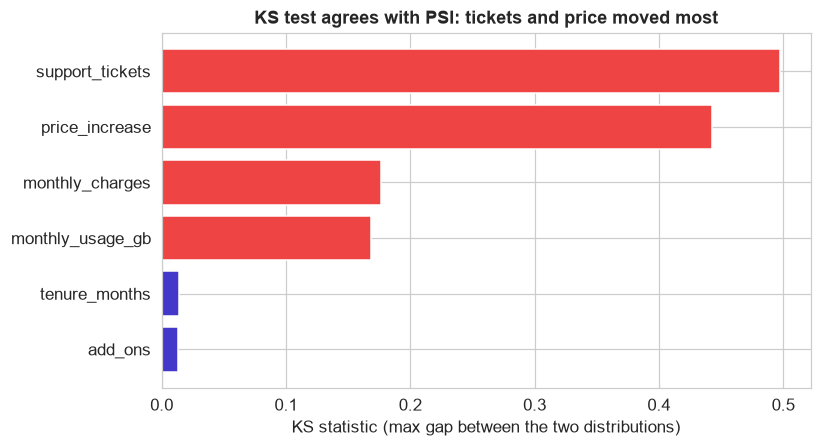

In [4]:
recent = df[df.month.between(13,18)]
print('Kolmogorov-Smirnov test: reference (m0) vs recent (m13-18)')
for f in FEATS:
    s,p = ks_2samp(ref[f].dropna(), recent[f].dropna())
    flag = '  <-- drift (p<0.001)' if p<0.001 else ''
    print(f'  {f:20s} KS={s:.3f}  p={p:.1e}{flag}')
fig,ax=plt.subplots(figsize=(7.6,4.2)); ks=[ks_2samp(ref[f].dropna(),recent[f].dropna()).statistic for f in FEATS]
order=np.argsort(ks); ax.barh([FEATS[i] for i in order],[ks[i] for i in order],color=[RED if ks[i]>0.15 else EM for i in order])
ax.set(xlabel='KS statistic (max gap between the two distributions)', title='KS test: tickets and price moved most'); plt.tight_layout(); plt.show()

**PSI is not the only drift detector.** The Kolmogorov-Smirnov test compares two distributions and returns a p-value. Here it flags four features, the two PSI flagged (tickets and price) plus monthly usage and monthly charges, whose PSI stayed below the 0.25 alert line. With thousands of rows on each side, KS calls even small shifts significant, so its p-value says a shift is real and does not say it is big enough to matter. Read the KS statistic itself, or PSI, for the size of the shift.

<div style="background:#eef2ff;border-left:5px solid #4338ca;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#3730a3;letter-spacing:1px">EXTENSION 2 &#183; WATCH THE MODEL'S OWN OUTPUT</span>
<div style="font-size:21px;font-weight:800;color:#1a2138;margin-top:4px">Prediction drift with no labels needed</div>
<div style="color:#4a5578;margin-top:6px">The score distribution shifts before you can score performance.</div>
</div>

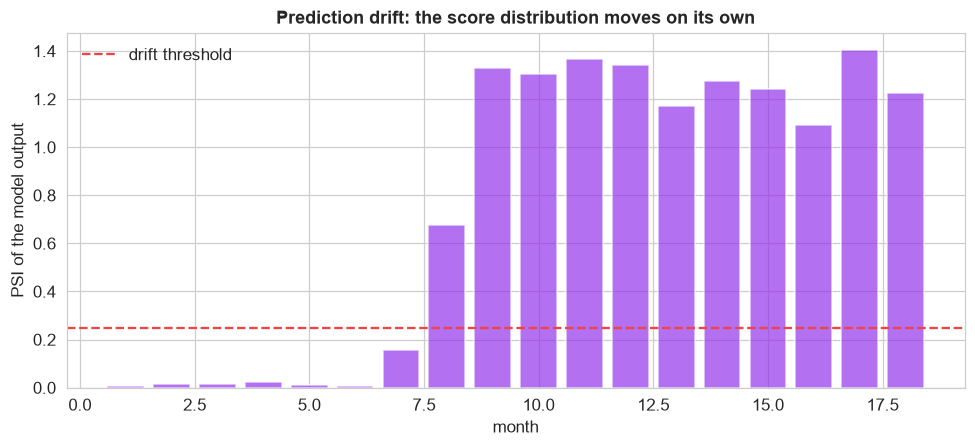

the model started predicting churn far more often (tickets rose) -- a label-free warning that something changed


In [5]:
def psi(a,b,bins=10):
    a=pd.Series(a).dropna(); b=pd.Series(b).dropna(); e=np.quantile(a,np.linspace(0,1,bins+1)); e[0]=-np.inf; e[-1]=np.inf
    r=np.clip(np.histogram(a,e)[0]/len(a),1e-4,None); c=np.clip(np.histogram(b,e)[0]/len(b),1e-4,None); return float(np.sum((c-r)*np.log(c/r)))
base_scores = df[df.month.between(1,3)].risk
pred_psi = [psi(base_scores, df[df.month==m].risk) for m in range(1,19)]
fig,ax=plt.subplots(figsize=(9,4.2))
ax.bar(range(1,19), pred_psi, color=PUR, alpha=0.7); ax.axhline(0.25,color=RED,ls='--',label='drift threshold')
ax.set(xlabel='month', ylabel='PSI of the model output', title='Prediction drift: the score distribution moves on its own'); ax.legend(); plt.tight_layout(); plt.show()
print('the model started predicting churn far more often (tickets rose) -- a label-free warning that something changed')

**You can monitor the model's own predictions.** Even with zero outcomes, the distribution of scores the model emits is observable, and here it drifts upward (the model sees more tickets, so it cries churn more often). Prediction drift is a second label-free tripwire, complementing input drift.

<div style="background:#eef2ff;border-left:5px solid #4338ca;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#3730a3;letter-spacing:1px">EXTENSION 3 &#183; HOW OFTEN TO RETRAIN?</span>
<div style="font-size:21px;font-weight:800;color:#1a2138;margin-top:4px">Never, monthly, or on-trigger</div>
<div style="color:#4a5578;margin-top:6px">Triggered retraining gets most of the benefit for a fraction of the cost.</div>
</div>

never     retrains  0 at months [] | mean AUC months 13-18 = 0.528
monthly   retrains 11 at months [7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17] | mean AUC months 13-18 = 0.739


triggered retrains  2 at months [7, 10] | mean AUC months 13-18 = 0.732


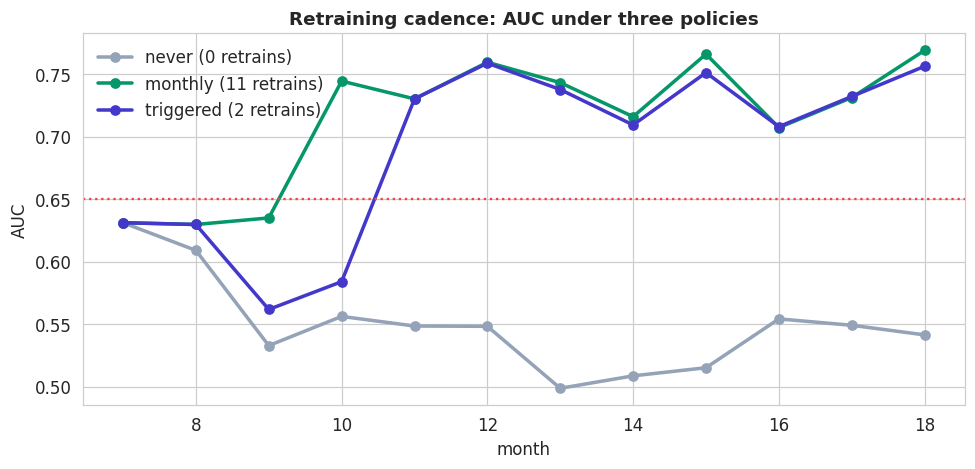

In [6]:
def rolling_auc(policy):
    aucs=[]; retrain_months=[]; model=champion; last_train=0; ref_t=ref.support_tickets
    for m in range(7,19):
        cur=df[df.month==m]; aucs.append(roc_auc_score(cur.churned, model.predict_proba(cur[FEATS])[:,1]))
        due = (policy=='monthly') or (policy=='triggered' and psi(ref_t, cur.support_tickets)>0.25 and m-last_train>=3)
        if due and m<18:
            win=df[df.month.between(m-2,m)]; model=fit(win); retrain_months.append(m); last_train=m
            ref_t=win.support_tickets          # the new model's training window becomes the drift reference
    return aucs, retrain_months
fig,ax=plt.subplots(figsize=(9,4.4)); mm=list(range(7,19))
for pol,c in [('never',GREY),('monthly',GREEN),('triggered',EM)]:
    a,r=rolling_auc(pol); ax.plot(mm,a,'o-',color=c,lw=2.3,label=f'{pol} ({len(r)} retrains)')
    print(f'{pol:9s} retrains {len(r):2d} at months {r} | mean AUC months 13-18 = {np.mean(a[6:]):.3f}')
ax.axhline(0.65,color=RED,ls=':'); ax.set(xlabel='month',ylabel='AUC',title='Retraining cadence: AUC under three policies'); ax.legend(); plt.tight_layout(); plt.show()

**More retraining is not automatically better.** Never retraining lets AUC rot. Retraining every single month keeps it high but is expensive and risks churn from constant model changes. **Triggered** retraining fires only when drift against the current model's own training window crosses the threshold, so after each retrain the reference resets. It retrains twice (months 7 and 10), lags monthly retraining in months 9 and 10, then matches it, averaging 0.732 over months 13 to 18 against monthly's 0.739 with 11 retrains, which makes cadence a trade between the cost of retraining and the model's freshness. For simplicity the demo trains on each month's labels as it arrives; with the contract's two-month label delay every retrain would land two months later.

<div style="background:#eef2ff;border-left:5px solid #4338ca;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#3730a3;letter-spacing:1px">EXTENSION 4 &#183; A ROLLBACK DRILL</span>
<div style="font-size:21px;font-weight:800;color:#1a2138;margin-top:4px">Catch a bad challenger before it ships</div>
<div style="color:#4a5578;margin-top:6px">The canary plus a rollback rule is your safety net.</div>
</div>

canary champion arm AUC 0.511 (n=483) | bad-challenger arm AUC 0.455 (n=117)
rollback rule (roll back if the challenger trails the champion by more than 0.02): ROLL BACK to champion


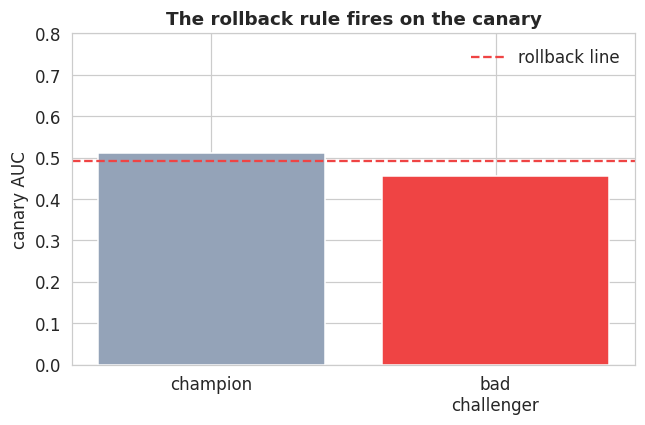

In [7]:
# a DELIBERATELY bad challenger: trained on the OLD regime (months 1-6), useless in the new normal
bad = fit(df[df.month.between(1,6)])
canary = df[df.month==14].copy(); rng=np.random.default_rng(1)
canary['arm']=np.where(rng.random(len(canary))<0.2,'challenger','champion')
auc_champ = roc_auc_score(canary[canary.arm=='champion'].churned, champion.predict_proba(canary[canary.arm=='champion'][FEATS])[:,1])
auc_bad   = roc_auc_score(canary[canary.arm=='challenger'].churned, bad.predict_proba(canary[canary.arm=='challenger'][FEATS])[:,1])
print(f'canary champion arm AUC {auc_champ:.3f} (n={(canary.arm=="champion").sum()}) | bad-challenger arm AUC {auc_bad:.3f} (n={(canary.arm=="challenger").sum()})')
decision = 'ROLL BACK to champion' if auc_bad < auc_champ - 0.02 else 'promote challenger'
print('rollback rule (roll back if the challenger trails the champion by more than 0.02):', decision)
fig,ax=plt.subplots(figsize=(6,4)); ax.bar(['champion','bad\nchallenger'],[auc_champ,auc_bad],color=[GREY,RED])
ax.axhline(auc_champ-0.02,color=RED,ls='--',label='rollback line'); ax.set(ylabel='canary AUC',ylim=(0,0.8),title='The rollback rule fires on the canary'); ax.legend(); plt.tight_layout(); plt.show()

**Not every challenger is an improvement.** Here a challenger trained on the stale old regime is no better than the aged champion. Because we shipped it as a small **canary** and armed a **rollback rule**, the rule fires on a slice of traffic and reverts it, never reaching all customers. Treat this as a drill of the mechanism. With the arm sizes printed above, each AUC carries several points of sampling error, so a gap this small is within noise, and a real canary would run larger or longer before trusting it. The demo also reads month-14 labels at once, where the contract's two-month label delay would push the decision to month 16.

<div style="background:#eef2ff;border-left:5px solid #4338ca;border-radius:10px;padding:16px 20px;font-family:Inter,sans-serif">
<span style="font-size:13px;font-weight:800;color:#3730a3;letter-spacing:1px">EXTENSION 5 &#183; WHEN IS IT SAFE TO PROMOTE?</span>
<div style="font-size:21px;font-weight:800;color:#1a2138;margin-top:4px">Shadow evaluation</div>
<div style="color:#4a5578;margin-top:6px">Score both models silently on months the challenger never trained on.</div>
</div>

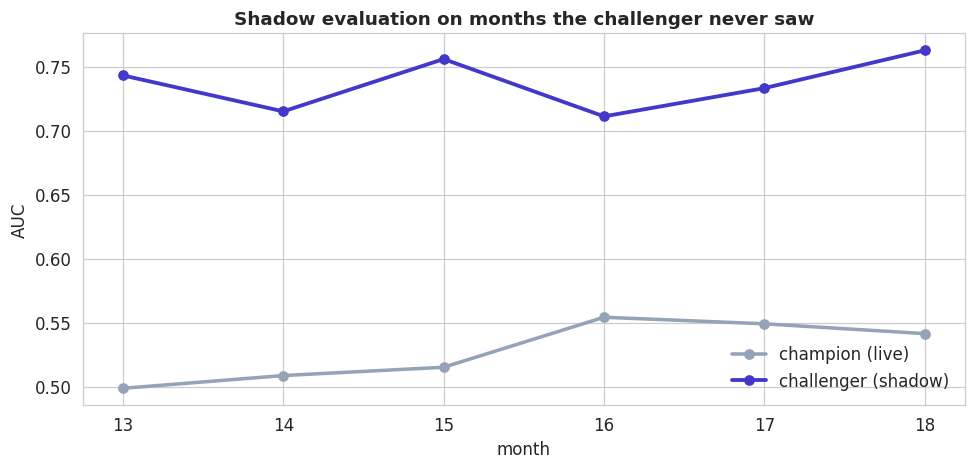

 month  champion  challenger
    13     0.499       0.743
    14     0.509       0.715
    15     0.515       0.756
    16     0.554       0.711
    17     0.549       0.733
    18     0.541       0.763
the challenger, scoring in shadow (not acting), beats the champion in 6 of 6 unseen months


In [8]:
good = fit(df[df.month.between(10,12)])   # the real challenger, trained on months 10-12
rows=[]
for m in range(13,19):                     # shadow-score only months it never trained on
    cur=df[df.month==m]
    rows.append({'month':m,'champion':roc_auc_score(cur.churned,champion.predict_proba(cur[FEATS])[:,1]),
                 'challenger':roc_auc_score(cur.churned,good.predict_proba(cur[FEATS])[:,1])})
shadow=pd.DataFrame(rows)
fig,ax=plt.subplots(figsize=(9,4.4)); ax.plot(shadow.month,shadow.champion,'o-',color=GREY,lw=2.3,label='champion (live)')
ax.plot(shadow.month,shadow.challenger,'o-',color=EM,lw=2.5,label='challenger (shadow)')
wins=int((shadow.challenger>shadow.champion).sum())
ax.set(xlabel='month',ylabel='AUC',title='Shadow evaluation on months the challenger never saw'); ax.legend(); plt.tight_layout(); plt.show()
print(shadow.round(3).to_string(index=False))
print(f'the challenger, scoring in shadow (not acting), beats the champion in {wins} of {len(shadow)} unseen months')

**Promote on evidence you can point to.** In **shadow** mode the challenger scores live traffic without acting, so you can compare it to the champion on identical, real data month after month. Here it leads in every one of the six months it never saw. Scoring it on its own training months (10 to 12) would have flattered it, which is why the comparison starts at month 13. Once it convincingly leads, you promote. This turns a risky guess into a monitored, reversible decision.

## What the extensions add to monitoring the churn model

- **Cross-check drift** with a second method: KS flags PSI's two features and two smaller shifts, and with large samples its p-values flag even small changes.
- **Monitor the model's own output**: prediction drift warns you with no labels at all.
- **Pick a retraining cadence**: triggered retraining nearly matches monthly at a fraction of the cost.
- **Always keep a rollback armed**: a canary catches a bad challenger before it reaches everyone.
- **Promote from shadow evidence**: run the challenger silently until it clearly wins.

---
<div style="text-align:center;color:#8b94b3;font-size:12px;margin-top:10px">Statistics, Data Science and AI: A Visual Handbook · © 2026 John Fisher</div>